# Stage 7 -- Explainability (SHAP)

We explain the trained champion (LightGBM pipeline) with exact tree SHAP
values. Tree boosters expose SHAP natively, so contributions reconstruct
the raw score exactly: `sum(SHAP) + base = model margin` (log-odds).

Preprocessing (median impute, p01/p99 cap, missing flags) runs before SHAP,
so contributions are attributed to the model-ready features. The reusable
logic lives in `src/modeling/explain.py`; the runnable report is
`python -m src.explain`.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import numpy as np
import matplotlib.pyplot as plt

from src.config import RANDOM_SEED
from src.modeling import load_model, load_modeling_data, compute_shap
from src.modeling import explain as ex

plt.rcParams['figure.dpi'] = 110

## Load champion and a holdout sample

In [2]:
model = load_model('champion')
data = load_modeling_data()

SAMPLE = 4000
X = data.X_holdout.sample(n=min(SAMPLE, len(data.X_holdout)), random_state=RANDOM_SEED)
y = data.y_holdout.loc[X.index]
print('explaining', len(X), 'rows;', int(y.sum()), 'defaults')

result = compute_shap(model, X)
proba = model.predict_proba(X)[:, 1]
margin = result.values.sum(axis=1).to_numpy() + result.base_value
recon = 1.0 / (1.0 + np.exp(-margin))
print('base value (log-odds):', round(result.base_value, 4))
print('max |proba - shap recon|:', float(np.max(np.abs(recon - proba))))

explaining 4000 rows; 337 defaults


base value (log-odds): -0.5782
max |proba - shap recon|: 2.7755575615628914e-15


The reconstruction error is at machine precision, confirming these are
exact SHAP values rather than an approximation.

## Global importance

In [3]:
imp = result.global_importance()
imp.head(20)

app_ext_source_2                   0.368328
app_ext_source_3                   0.286489
app_ext_source_1                   0.189373
app_credit_to_goods                0.141491
app_years_employed                 0.138514
prev_credit_to_application_mean    0.135460
app_amt_annuity                    0.121646
pos_months_count                   0.101857
bur_utilisation                    0.091205
app_age_years                      0.083097
prev_refused_rate                  0.078114
pos_future_inst_trend              0.077188
app_amt_credit                     0.068353
inst_late_rate_12m                 0.066181
inst_count                         0.064253
inst_dpd_max                       0.059322
inst_late_rate                     0.054507
app_annuity_to_income              0.046333
bur_amt_credit_sum_mean            0.044970
inst_late_rate_6m_was_missing      0.039855
dtype: float64

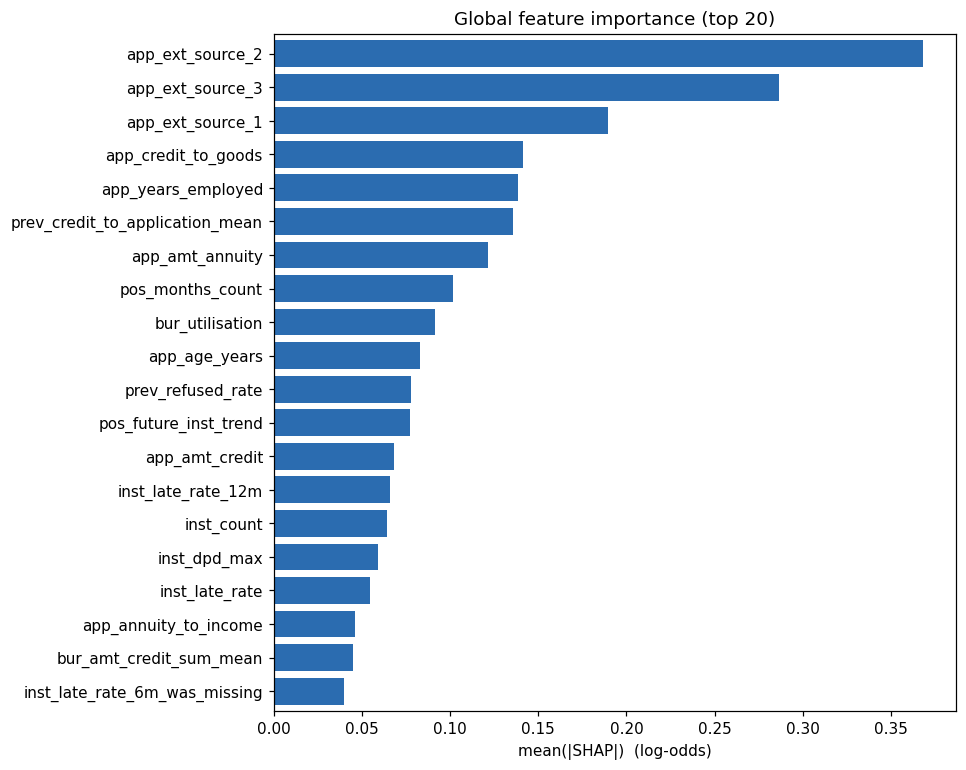

In [4]:
fig, ax = plt.subplots(figsize=(8, 8))
ex.plot_global_bar(result, ax=ax, top=20)
plt.show()

## SHAP summary (beeswarm)

Color encodes the feature value (red = high). For the external scores,
high values (red) sit on the negative side -- a higher external credit
score lowers predicted default risk, as expected.

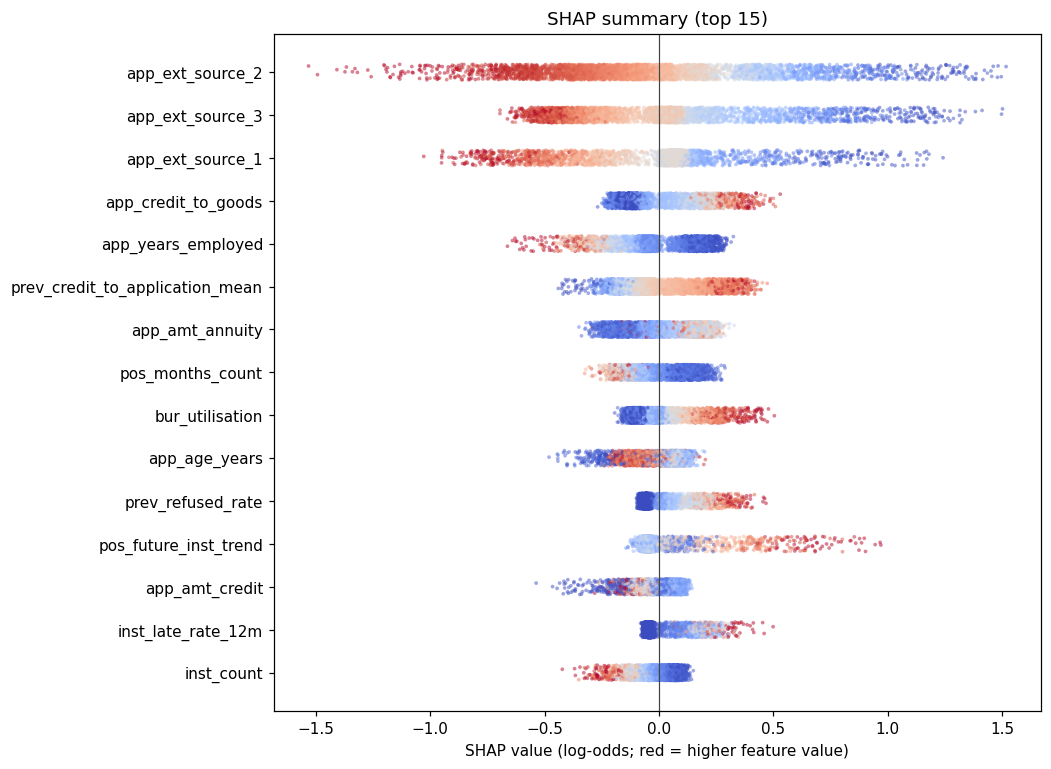

In [5]:
fig, ax = plt.subplots(figsize=(9, 8))
ex.plot_beeswarm(result, ax=ax, top=15)
plt.show()

## Dependence plots for the top drivers

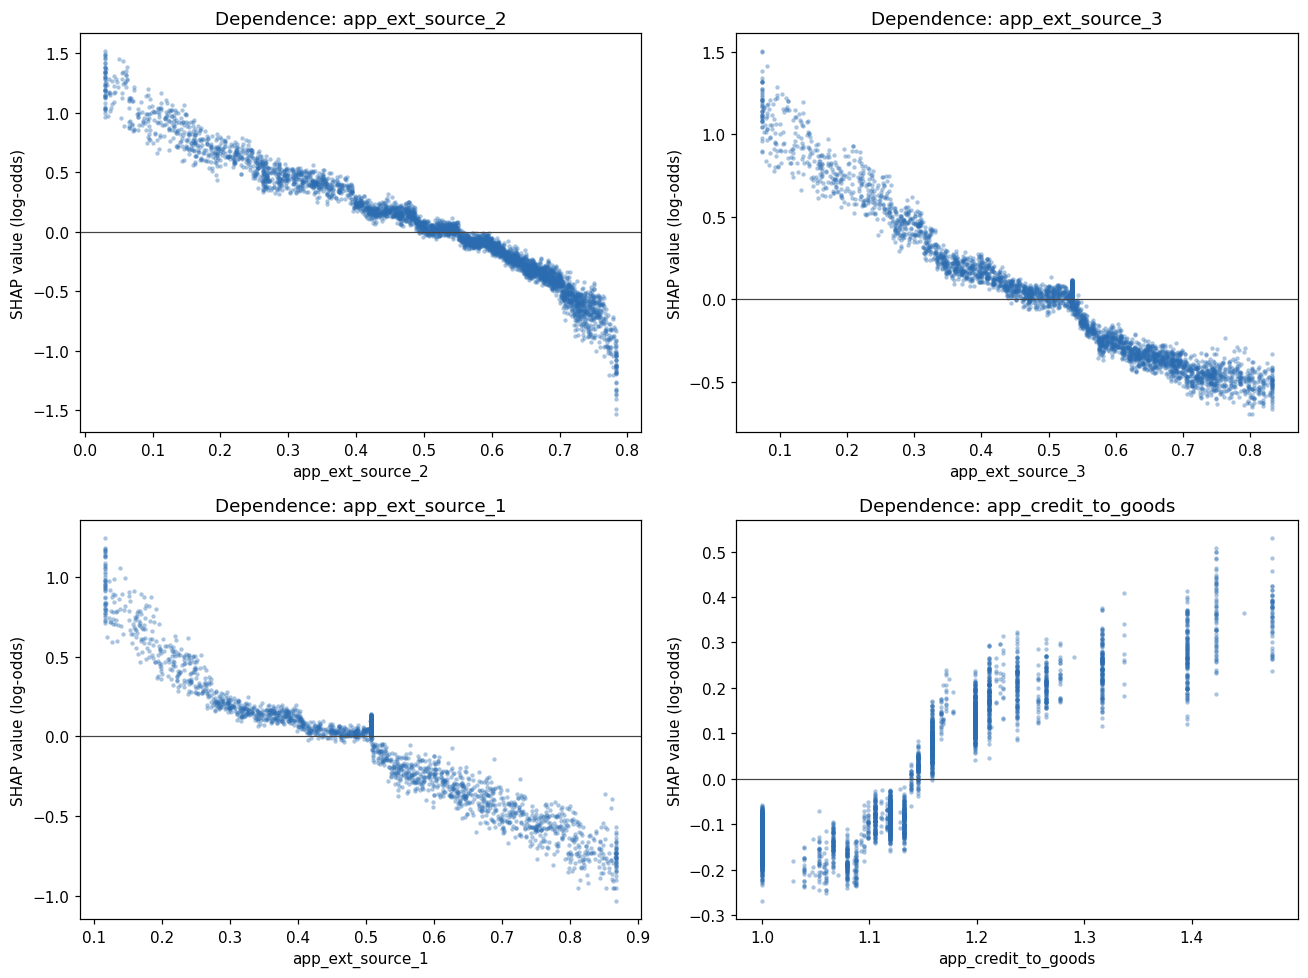

In [6]:
top_feats = result.top_features(4)
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for feat, ax in zip(top_feats, axes.ravel()):
    ex.plot_dependence(result, feat, ax=ax)
fig.tight_layout()
plt.show()

## Local explanations

Individual applicants at the extremes of predicted risk. Red bars raise
default risk, green bars lower it.

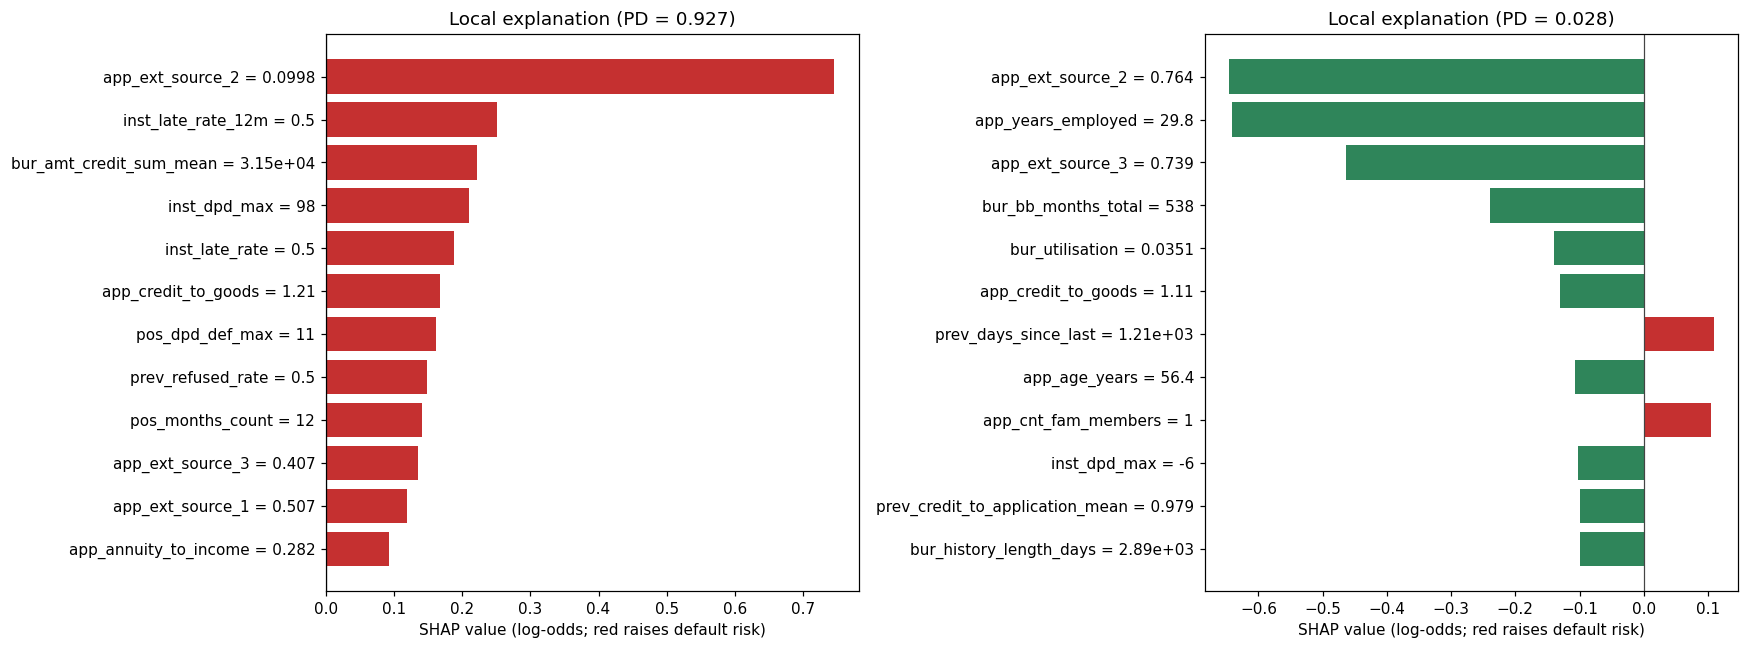

In [7]:
hi = int(np.argmax(proba))
lo = int(np.argmin(proba))
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
ex.plot_waterfall(result, row=hi, ax=axes[0], top=12)
ex.plot_waterfall(result, row=lo, ax=axes[1], top=12)
fig.tight_layout()
plt.show()

## Takeaways

- The three external credit scores dominate, followed by affordability
  ratios (credit-to-goods, annuity) and repayment history (installment
  lateness, POS/bureau behaviour).
- Signed contributions match intuition: weaker external scores, higher
  leverage, and past lateness all push predicted default up.
- Reported artifacts are regenerated by the pipeline via
  `python -m src.explain`, writing `reports/explainability.md` and the
  `reports/figures/shap_*.png` plots.